# LOBT window

The NM flight data contain the LOBT (last known off-block time). The question here is how far the real off-block can be
from it. If the distance is bounded, the label is bounded by `MVT − LOBT` plus or minus that distance, a hard limit
that no model has to learn.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "pyproject.toml").is_file())
FEATURES = ROOT / "data/03_features"

In [2]:
columns = ["ADEP_mvt", "MVT_TIME_UTC_mvt", "SCHED_TIME_UTC_mvt", "LOBT_flt", "TAXITIME_SEC_mvt"]
train = pd.read_parquet(FEATURES / "train_DEP_merged_sorted.parquet", columns=columns)
train = train.loc[pd.to_datetime(train["SCHED_TIME_UTC_mvt"], utc=True).dt.year.eq(2025)].reset_index(drop=True)
train["month"] = pd.to_datetime(train["MVT_TIME_UTC_mvt"], utc=True).dt.month
print(f"{len(train):,} departures in 2025")

2,085,041 departures in 2025


In [3]:
gap = (pd.to_datetime(train["MVT_TIME_UTC_mvt"], utc=True) - pd.to_datetime(train["LOBT_flt"], utc=True)).dt.total_seconds()
offset = (train["TAXITIME_SEC_mvt"] - gap)[gap.notna()]
print(f"Departures with an LOBT: {gap.notna().mean():.1%}")
print(f"Label within MVT - LOBT +/- 3606 s: {offset.abs().le(3606).mean():.4%}")
offset.describe(percentiles=[.001, .01, .5, .99, .999]).round(0)

Departures with an LOBT: 98.9%
Label within MVT - LOBT +/- 3606 s: 100.0000%


count    2062574.0
mean        -366.0
std          643.0
min        -3606.0
0.1%       -3474.0
1%         -2623.0
50%         -251.0
99%          838.0
99.9%       2336.0
max         3606.0
dtype: float64

### Distribution of label − (MVT − LOBT)

The off-block lies within about one hour of the LOBT, with a sharp edge at ±3606 s.

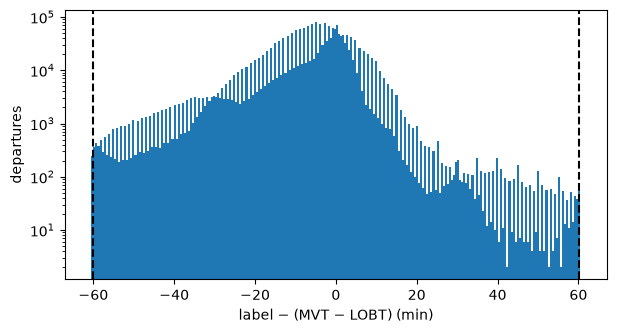

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(offset / 60, bins=240, range=(-61, 61))
ax.axvline(-60.1, color="k", ls="--"); ax.axvline(60.1, color="k", ls="--")
ax.set(xlabel="label − (MVT − LOBT) (min)", ylabel="departures", yscale="log")
plt.show()

### Per airport and month

A limit is only safe if it holds everywhere, not just on average.

In [5]:
pd.DataFrame({"inside": offset.abs().le(3606).groupby(train.loc[offset.index, "ADEP_mvt"]).mean(),
              "largest |offset| (s)": offset.abs().groupby(train.loc[offset.index, "ADEP_mvt"]).max()}).round(4)

,inside,largest |offset| (s)
ADEP_mvt,,
EDDF,1.0,3605.0
EDDM,1.0,3606.0
EGLL,1.0,3606.0
EHAM,1.0,3602.0
LEBL,1.0,3606.0
LEMD,1.0,3606.0
LFPG,1.0,3606.0
LIRF,1.0,3606.0
LSZH,1.0,3602.0


In [6]:
offset.abs().le(3606).groupby(train.loc[offset.index, "month"]).mean().round(5).to_frame("inside")

,inside
month,
1,1.0
2,1.0
3,1.0
4,1.0
5,1.0
6,1.0
7,1.0
8,1.0
9,1.0


### What follows for the models

Every 2025 label of a departure with an LOBT lies within `MVT − LOBT ± 3606 s`, at every airport and in every month.
Every prediction is therefore moved into this window (`runner.lobt_window`). The window is wide for normal flights
but cuts off implausible values for delayed ones.